In [63]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import os
from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
DATASET_DIR = Path("PetImages")

if not DATASET_DIR.exists(): # Checking folder
    DATASET_DIR = Path("Prediction_Cat_Dog/PetImages")
# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".gif"
}

In [65]:
if not DATASET_DIR.exists():
    raise FileNotFoundError("Dataset directory not found!")

print("Lokasi dataset:", DATASET_DIR.resolve())
print("Folder kelas:", os.listdir(DATASET_DIR))

Lokasi dataset: D:\Data Sciend and AI Engeener\Deployment_web\Prediction_Cat_Dog\PetImages
Folder kelas: ['Cat', 'Dog']


In [66]:
image_files = [
    file for file in DATASET_DIR.rglob("*")
    if file.suffix.lower() in IMAGE_EXTENSIONS
]

total_images = len(image_files)

print("Total number of images:", total_images)

Total number of images: 24998


In [67]:

DATASET_DIR = Path("PetImages")

# periksa jumlah gambar di setiap kelas.
class_names = ["Cat", "Dog"]

for class_name in class_names:
    folder = DATASET_DIR / class_name # mengabungkan path 

    image_files = [
        f for f in folder.iterdir()
        if f.is_file()
    ]

    print(f"{class_name}: {len(image_files)} file")

Cat: 12499 file
Dog: 12499 file


In [68]:
from pathlib import Path
from PIL import Image

DATASET_DIR = Path("PetImages")
class_names = ["Cat", "Dog"]

invalid_files = []
unusual_modes = []

for class_name in class_names:
    folder = DATASET_DIR / class_name

    if not folder.is_dir():
        print("Folder kelas tidak ditemukan:", folder)
        continue

    for file_path in folder.iterdir():
        if not file_path.is_file():
            continue

        try:
            # Pemeriksaan integritas file
            with Image.open(file_path) as img:
                img.verify()

            # Buka ulang untuk membaca piksel
            with Image.open(file_path) as img:
                img.load()

                if img.mode not in ["RGB", "RGBA", "L"]:
                    unusual_modes.append(
                        (str(file_path), img.mode)
                    )

        except Exception as e:
            invalid_files.append(str(file_path))
            print("Gambar bermasalah:", file_path, "|", e)

print("\nJumlah gambar tidak valid:", len(invalid_files))
print("Jumlah gambar dengan mode warna tidak biasa:", len(unusual_modes))

print("\nContoh gambar tidak valid:")
for path in invalid_files[:10]:
    print(path)

print("\nContoh mode warna tidak biasa:")
for path, mode in unusual_modes[:10]:
    print(path, "| Mode:", mode)

c:\Users\saire\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Jumlah gambar tidak valid: 0
Jumlah gambar dengan mode warna tidak biasa: 60

Contoh gambar tidak valid:

Contoh mode warna tidak biasa:
PetImages\Cat\10125.jpg | Mode: P
PetImages\Cat\10501.jpg | Mode: P
PetImages\Cat\10820.jpg | Mode: P
PetImages\Cat\11095.jpg | Mode: P
PetImages\Cat\11210.jpg | Mode: P
PetImages\Cat\11565.jpg | Mode: P
PetImages\Cat\11874.jpg | Mode: P
PetImages\Cat\11935.jpg | Mode: P
PetImages\Cat\12080.jpg | Mode: P
PetImages\Cat\140.jpg | Mode: P


In [69]:
import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split

image_paths = []
labels = []

for class_name in class_names:

    class_dir = DATASET_DIR / class_name

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            image_paths.append(image_path)
            labels.append(class_name)

print("colection label and path success")

colection label and path success


In [70]:
# =====================================
# 3. Split Train and Temporary Data
# =====================================

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# =====================================
# 4. Split Validation and Test
# =====================================

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [71]:
# =====================================
# 5. Copy Images into Folders
# =====================================
OUTPUT_DIR = Path("PetImages_Split")

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

def save_images(paths, labels, split_name):

    for image_path, label in zip(paths, labels):

        destination = OUTPUT_DIR / split_name / label

        destination.mkdir(parents=True, exist_ok=True)

        shutil.copy2(
            image_path,
            destination / image_path.name
        )

save_images(X_train, y_train, "train")
save_images(X_val, y_val, "validation")
save_images(X_test, y_test, "test")

In [72]:
# =====================================
# 6. Display Results
# =====================================

print("Dataset Splitting Completed!")

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Dataset Splitting Completed!
Training: 17498
Validation: 3750
Testing: 3750


In [82]:
from pathlib import Path
from PIL import Image

# =====================================
# 1. Configuration
# =====================================

SOURCE_DIR = Path("PetImages_Split")
OUTPUT_DIR = Path("PetImages_Split_Clean")

IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]

fixed_images = 0
removed_images = 0

# =====================================
# 2. Image Cleaning
# =====================================

for image_path in SOURCE_DIR.rglob("*"):

    if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    try:
        # Open and read image
        with Image.open(image_path) as img:

            # Convert to RGB
            rgb_image = img.convert("RGB")

            # Create destination folder
            relative_path = image_path.relative_to(SOURCE_DIR)

            destination = OUTPUT_DIR / relative_path.with_suffix(".jpg")

            destination.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            # Save as new JPEG file
            rgb_image.save(destination, format="JPEG")

            fixed_images += 1

    except Exception as e:

        print("Skipped:", image_path)
        print("Reason:", e)

        removed_images += 1


print("\nImage Cleaning Completed!")
print("Converted Images:", fixed_images)
print("Skipped Images:", removed_images)

c:\Users\saire\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Image Cleaning Completed!
Converted Images: 24998
Skipped Images: 0


In [84]:
# =====================================
# 1. Configuration
# =====================================
import tensorflow as tf

IMG_SIZE = (160 , 160 )
BATCH_SIZE = 32


In [83]:
# =====================================
# 2. Load Training Dataset
# =====================================
from pathlib import Path
FOLDER_SPLIT = Path("PetImages_Split_Clean")
CLASS_FOLDER = ["Cat", "Dog"]

train_dataset = tf.keras.utils.image_dataset_from_directory(
    FOLDER_SPLIT/"train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=CLASS_FOLDER,
    shuffle=True,
    seed=42
)


Found 17498 files belonging to 2 classes.


In [85]:
# =====================================
# 3. Load Validation Dataset
# =====================================

val_dataset = tf.keras.utils.image_dataset_from_directory(
    FOLDER_SPLIT/"validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=CLASS_FOLDER,
    shuffle=False
)


Found 3750 files belonging to 2 classes.


In [86]:
# =====================================
# 4. Load Testing Dataset
# =====================================

test_dataset = tf.keras.utils.image_dataset_from_directory(
    FOLDER_SPLIT/"test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=CLASS_FOLDER,
    shuffle=False
)

Found 3750 files belonging to 2 classes.


In [87]:
import tensorflow as tf
from tensorflow.keras import layers, models

# =====================================
# 1. Configuration
# =====================================

IMG_SIZE = (160, 160)

# =====================================
# 2. Resizing
# =====================================

resize_layer = layers.Resizing(
    height=IMG_SIZE[0],
    width=IMG_SIZE[1]
)

# =====================================
# 3. Normalization
# =====================================

normalization_layer = layers.Rescaling(1.0 / 255)

# =====================================
# 4. Data Augmentation
# =====================================

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05)
])

In [ ]:
model = models.Sequential([

    # =====================================
    # Input
    # =====================================

    layers.Input(shape=(160, 160, 3)),

    # =====================================
    # Preprocessing
    # =====================================

    resize_layer,
    normalization_layer,
    data_augmentation,

    # =====================================
    # Convolution Block 1
    # =====================================

    layers.Conv2D(
        32, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(pool_size=2),

    # =====================================
    # Convolution Block 2
    # =====================================

    layers.Conv2D(
        64, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(pool_size=2),

    # =====================================
    # Convolution Block 3
    # =====================================

    layers.Conv2D(
        128, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(pool_size=2),

    # =====================================
    # Flatten
    # =====================================

    layers.Flatten(),

    # =====================================
    # Fully Connected
    # =====================================

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # =====================================
    # Output    
    # =====================================

    layers.Dense(1, activation="sigmoid")

])

model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_5 (Resizing)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_10 (Sequential)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [89]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [91]:
# =====================================
# 2. Early Stopping
# =====================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


# =====================================
# 3. Model Training
# =====================================

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=25,
    callbacks=[early_stopping]
)

Epoch 1/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 150s 274ms/step - accuracy: 0.6354 - loss: 0.6334 - val_accuracy: 0.7171 - val_loss: 0.5654
Epoch 2/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 142s 260ms/step - accuracy: 0.7195 - loss: 0.5536 - val_accuracy: 0.7283 - val_loss: 0.5290
Epoch 3/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 145s 266ms/step - accuracy: 0.7530 - loss: 0.5089 - val_accuracy: 0.7565 - val_loss: 0.4845
Epoch 4/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 148s 271ms/step - accuracy: 0.7732 - loss: 0.4727 - val_accuracy: 0.7976 - val_loss: 0.4391
Epoch 5/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 152s 278ms/step - accuracy: 0.8011 - loss: 0.4368 - val_accuracy: 0.8085 - val_loss: 0.4242
Epoch 6/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 155s 284ms/step - accuracy: 0.8179 - loss: 0.4047 - val_accuracy: 0.8328 - val_loss: 0.3843
Epoch 7/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 156s 285ms/step - accuracy: 0.8293 - loss: 0.3789 - val_accuracy: 0.8363 - val_loss: 0.3753
Epoch 8/25
547/547 ━━━━━━━━━━━━━━━━━━━━ 158s 289ms/step - accuracy: 0.8410 -

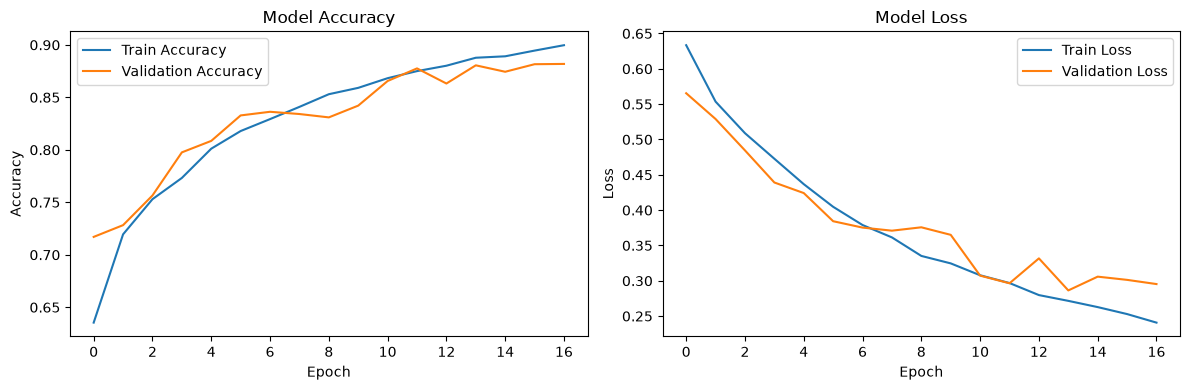

In [92]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

         Cat       0.88      0.88      0.88      1875
         Dog       0.88      0.88      0.88      1875

    accuracy                           0.88      3750
   macro avg       0.88      0.88      0.88      3750
weighted avg       0.88      0.88      0.88      3750



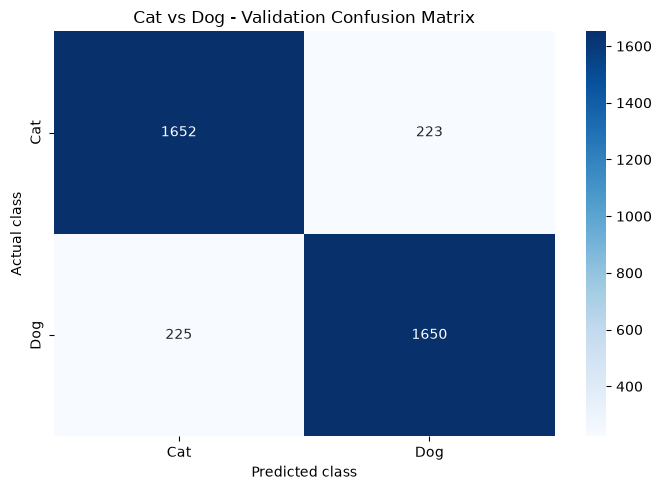

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Jangan tulis ulang:
# class_names = train_ds.class_names
# Gunakan class_names yang sudah disimpan sebelumnya.

# Actual labels
y_true = np.concatenate([
    labels.numpy().ravel().astype(int)
    for _, labels in val_dataset
])

# Predicted labels
y_pred = np.concatenate([
    (model.predict(images, verbose=0).ravel() >= 0.5).astype(int)
    for images, _ in val_dataset
])

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Cat vs Dog - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [94]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

y_pred = model.predict(test_dataset)

y_pred = (y_pred > 0.5).astype(int).flatten()

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))

118/118 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step
              precision    recall  f1-score   support

         Cat       0.90      0.87      0.89      1875
         Dog       0.88      0.91      0.89      1875

    accuracy                           0.89      3750
   macro avg       0.89      0.89      0.89      3750
weighted avg       0.89      0.89      0.89      3750



In [95]:

# Save trained CNN model

model.save("cnn_dog_cat2.keras")

print("Model successfully saved!")


Model successfully saved!
